# explore_prepared_v2 — EDA ชุดข้อมูลหลังเตรียมเสร็จ

อ่านจาก `processed/prepared_v2/` **อย่างเดียว ไม่เขียนดิสก์**

ลำดับ: ภาพรวม → Y (JV) → mediator (VTFL) → X knob → composition → stability → missingness → ข้อสังเกต
ทุก correlation ในนี้ = naive (ยังไม่คุม paper) ใช้ดูทิศทางเท่านั้น รอ LOPO ตัดสิน

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"
t = {p.stem: pd.read_csv(p) for p in sorted(V2.glob("*.csv"))}
tt = t["target_table"].copy()
tt["paper"] = tt["device_id"].str.rsplit("_Sample", n=1).str[0]

# palette (validated default) + สไตล์: เส้นบาง กริดจาง แกนเงียบ
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": ["Leelawadee UI", "Tahoma", "DejaVu Sans"],
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})

print("โหลด:", ", ".join(f"{n} {d.shape}" for n, d in t.items()))
print(f"devices {tt.device_id.nunique()} | papers {tt.paper.nunique()}")

โหลด: device_layer_flags (44, 10), devices (44, 13), layers (352, 11), materials (543, 13), process (702, 71), properties (563, 16), psk_composition (44, 11), stability (62, 20), target_table (44, 32), vendors (644, 8)
devices 44 | papers 15


## 1. ภาพรวม coverage — คอลัมน์ไหนมีข้อมูลกี่ device

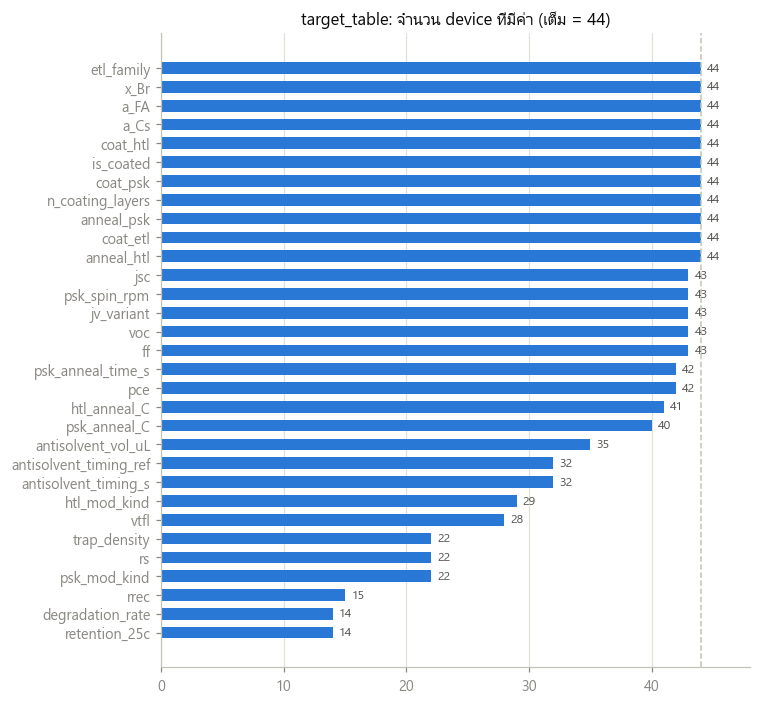

กลุ่ม coverage:
  ครบ/เกือบครบ (40+): psk_anneal_C, htl_anneal_C, pce, psk_anneal_time_s, ff, voc, jv_variant, psk_spin_rpm, jsc, anneal_htl, coat_etl, anneal_psk, n_coating_layers, coat_psk, is_coated, coat_htl, a_Cs, a_FA, x_Br, etl_family
  กลาง (20-39):       psk_mod_kind, rs, trap_density, vtfl, htl_mod_kind, antisolvent_timing_s, antisolvent_timing_ref, antisolvent_vol_uL
  น้อย (<20):         retention_25c, degradation_rate, rrec


In [2]:
cov = tt.drop(columns=["device_id", "paper"]).notna().sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(cov.index, cov.values, color=C1, height=0.62)
ax.axvline(44, color=BASE, lw=1, ls="--")
for i, v in enumerate(cov.values):
    ax.text(v + 0.5, i, str(v), va="center", color=INK2, fontsize=8)
ax.set_xlim(0, 48); ax.grid(axis="y", visible=False)
ax.set_title("target_table: จำนวน device ที่มีค่า (เต็ม = 44)")
plt.tight_layout(); plt.show()

print("กลุ่ม coverage:")
print("  ครบ/เกือบครบ (40+):", ", ".join(cov[cov >= 40].index))
print("  กลาง (20-39):      ", ", ".join(cov[(cov >= 20) & (cov < 40)].index))
print("  น้อย (<20):        ", ", ".join(cov[cov < 20].index))

## 2. Y ประสิทธิภาพ — การกระจาย + variant

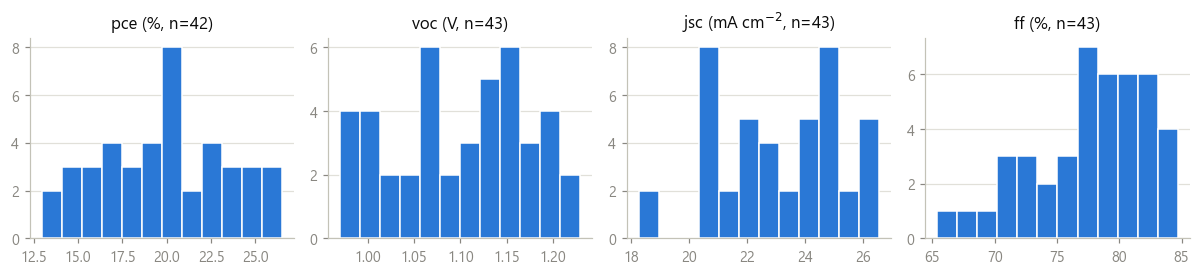

jv_variant: {'champion': 23, 'plain': 16, 'average': 4}
pce vs voc*jsc*ff/100: max_err 0.503 (rounding เท่านั้น -- variant-consistent แล้ว)


,count,mean,std,min,25%,50%,75%,max
pce,42.0,19.95,3.62,12.94,17.00,20.16,22.80,26.50
voc,43.0,1.10,0.07,0.97,1.04,1.11,1.15,1.23
jsc,43.0,23.14,2.14,18.26,21.36,23.49,24.72,26.55
ff,43.0,77.71,4.70,65.39,75.10,78.46,81.19,84.68


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6))
for ax, c, unit in zip(axes, ["pce", "voc", "jsc", "ff"], ["%", "V", "mA cm$^{-2}$", "%"]):
    ax.hist(tt[c].dropna(), bins=12, color=C1, edgecolor="white", linewidth=1)
    ax.set_title(f"{c} ({unit}, n={int(tt[c].notna().sum())})")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("jv_variant:", tt["jv_variant"].value_counts().to_dict())
h = tt.dropna(subset=["voc", "jsc", "ff", "pce"])
err = (h.voc * h.jsc * h.ff / 100 - h.pce).abs()
print(f"pce vs voc*jsc*ff/100: max_err {err.max():.3f} (rounding เท่านั้น -- variant-consistent แล้ว)")
display(tt[["pce", "voc", "jsc", "ff"]].describe().T.round(2))

## 3. PCE รายห้อง (paper) — ดู confound ที่ต้องคุมด้วย LOPO

ถ้า variation ระหว่าง paper ใหญ่กว่าใน paper มาก = สัญญาณ knob จะปนกับ "ฝีมือแล็บ" — ต้อง LeaveOneGroupOut

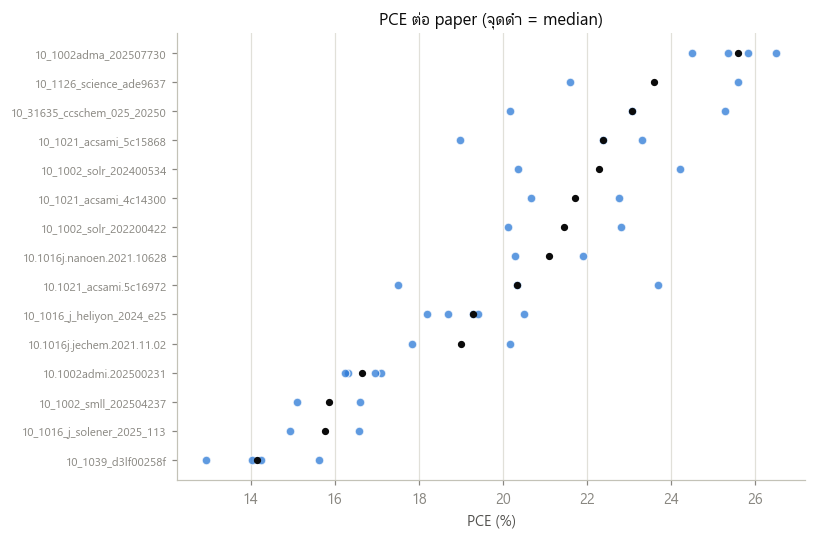

variance ระหว่าง paper 10.5 vs เฉลี่ยใน paper 3.5 -> ระหว่างใหญ่กว่า ~3 เท่า = confound จริง ต้อง LOPO


In [4]:
order = tt.groupby("paper")["pce"].median().sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 5))
for i, p in enumerate(order):
    v = tt.loc[tt.paper == p, "pce"].dropna()
    ax.scatter(v, [i] * len(v), color=C1, s=32, alpha=0.75, edgecolor="white", linewidth=0.8)
    ax.scatter(v.median(), i, color=INK, s=14, zorder=3)
ax.set_yticks(range(len(order)), [p[:26] for p in order], fontsize=7.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PCE (%)"); ax.set_title("PCE ต่อ paper (จุดดำ = median)")
plt.tight_layout(); plt.show()

aov = tt.dropna(subset=["pce"]).groupby("paper")["pce"]
between = aov.mean().var(); within = aov.var().mean()
print(f"variance ระหว่าง paper {between:.1f} vs เฉลี่ยใน paper {within:.1f} -> ระหว่างใหญ่กว่า ~{between/within:.0f} เท่า = confound จริง ต้อง LOPO")

## 4. Mediator: VTFL (ตัวแทน grain/trap ที่ coverage ดีสุด 28 dev)

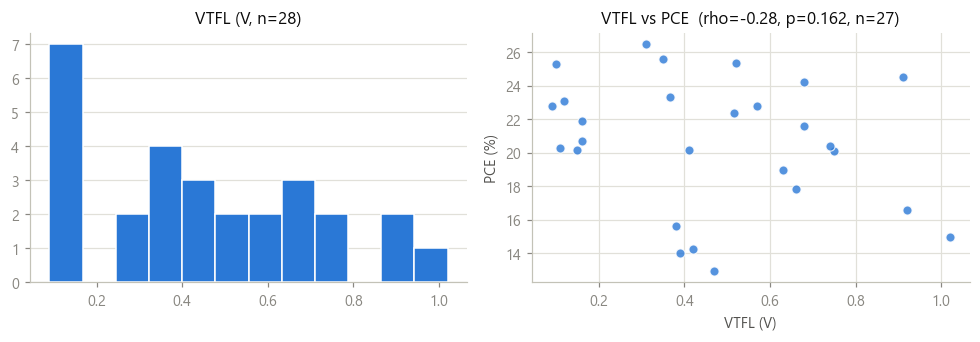

เช็คว่า VTFL แทน trap ได้: vtfl vs trap_density rho=+0.76 (n=19) -- ทฤษฎีคาดบวก (VTFL สูง = trap เยอะ)


In [5]:
from scipy import stats as ss

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(tt["vtfl"].dropna(), bins=12, color=C1, edgecolor="white", linewidth=1)
axes[0].set_title(f"VTFL (V, n={int(tt.vtfl.notna().sum())})"); axes[0].grid(axis="x", visible=False)

s = tt.dropna(subset=["vtfl", "pce"])
axes[1].scatter(s.vtfl, s.pce, color=C1, s=36, alpha=0.8, edgecolor="white", linewidth=0.8)
rho, pv = ss.spearmanr(s.vtfl, s.pce)
axes[1].set_xlabel("VTFL (V)"); axes[1].set_ylabel("PCE (%)")
axes[1].set_title(f"VTFL vs PCE  (rho={rho:+.2f}, p={pv:.3f}, n={len(s)})")
plt.tight_layout(); plt.show()

s2 = tt.dropna(subset=["vtfl", "trap_density"])
if len(s2) >= 8:
    r2, p2 = ss.spearmanr(s2.vtfl, s2.trap_density)
    print(f"เช็คว่า VTFL แทน trap ได้: vtfl vs trap_density rho={r2:+.2f} (n={len(s2)}) -- ทฤษฎีคาดบวก (VTFL สูง = trap เยอะ)")

## 5. X knob — การกระจายของตัวแปร process

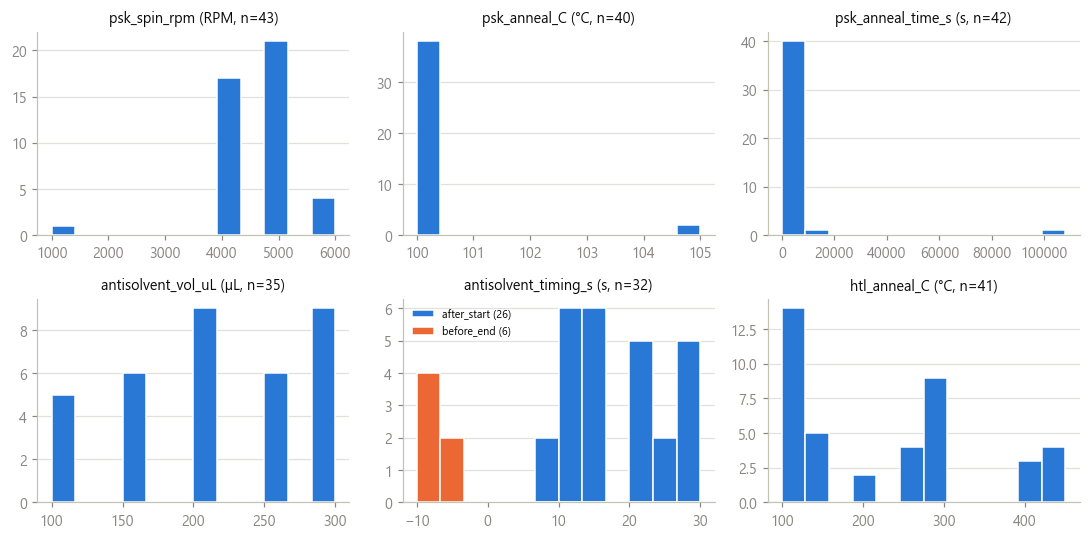

หมายเหตุ: psk_anneal_C กับ htl_anneal_C คนละสเกลจริง (PSK ~100-150, HTL/NiOx สูงถึง 450) -- แยกคอลัมน์แล้ว ห้ามรวม


In [6]:
knobs = [("psk_spin_rpm", "RPM"), ("psk_anneal_C", "°C"), ("psk_anneal_time_s", "s"),
         ("antisolvent_vol_uL", "µL"), ("antisolvent_timing_s", "s"), ("htl_anneal_C", "°C")]
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, (c, unit) in zip(axes.ravel(), knobs):
    if c == "antisolvent_timing_s":
        # 2 จุดอ้างอิง -- แยกสี ห้ามรวมสเกล
        a = tt.loc[tt.antisolvent_timing_ref == "after_start", c].dropna()
        b = tt.loc[tt.antisolvent_timing_ref == "before_end", c].dropna()
        bins = np.histogram_bin_edges(tt[c].dropna(), bins=12)
        ax.hist(a, bins=bins, color=C1, edgecolor="white", linewidth=1, label=f"after_start ({len(a)})")
        ax.hist(b, bins=bins, color=C2, edgecolor="white", linewidth=1, label=f"before_end ({len(b)})")
        ax.legend(fontsize=7, frameon=False)
    else:
        ax.hist(tt[c].dropna(), bins=12, color=C1, edgecolor="white", linewidth=1)
    ax.set_title(f"{c} ({unit}, n={int(tt[c].notna().sum())})", fontsize=9.5)
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("หมายเหตุ: psk_anneal_C กับ htl_anneal_C คนละสเกลจริง (PSK ~100-150, HTL/NiOx สูงถึง 450) -- แยกคอลัมน์แล้ว ห้ามรวม")

## 6. knob vs Y — spearman (naive) + scatter

⚠️ ตัวเลขชุดนี้ยังไม่คุม paper — ใช้เลือกตัวที่ "ควรไปทดสอบต่อใน LOPO" เท่านั้น

In [7]:
ys = ["pce", "voc", "ff", "vtfl", "retention_25c"]
rows = []
for k, _ in knobs:
    for y in ys:
        s = tt[[k, y]].dropna()
        if len(s) >= 10:
            rho, pv = ss.spearmanr(s[k], s[y])
            rows.append({"knob": k, "y": y, "n": len(s), "rho": round(rho, 2), "p": round(pv, 3)})
sp = pd.DataFrame(rows).pivot(index="knob", columns="y", values="rho")
n_tab = pd.DataFrame(rows).pivot(index="knob", columns="y", values="n")
print("spearman rho (naive):"); display(sp)
print("n:"); display(n_tab)

top = (pd.DataFrame(rows).assign(a=lambda d: d.rho.abs())
       .query("a >= 0.3").sort_values("a", ascending=False))
print("คู่ที่ |rho| >= 0.3 (คัดไปทดสอบใน LOPO):"); display(top.drop(columns="a"))

spearman rho (naive):


y,ff,pce,retention_25c,voc,vtfl
knob,,,,,
antisolvent_timing_s,0.21,0.44,0.06,0.52,-0.33
antisolvent_vol_uL,-0.15,-0.17,0.16,-0.15,0.16
htl_anneal_C,-0.74,-0.56,-0.42,-0.64,-0.29
psk_anneal_C,0.09,0.14,0.10,0.02,-0.38
psk_anneal_time_s,0.25,0.10,-0.23,0.36,0.04
psk_spin_rpm,-0.07,-0.08,-0.35,-0.21,0.57


n:


y,ff,pce,retention_25c,voc,vtfl
knob,,,,,
antisolvent_timing_s,32,32,12,32,19
antisolvent_vol_uL,34,34,12,34,21
htl_anneal_C,40,39,13,40,27
psk_anneal_C,39,38,11,39,25
psk_anneal_time_s,41,40,12,41,26
psk_spin_rpm,42,41,13,42,27


คู่ที่ |rho| >= 0.3 (คัดไปทดสอบใน LOPO):


,knob,y,n,rho,p
27,htl_anneal_C,ff,40,-0.74,0.000
26,htl_anneal_C,voc,40,-0.64,0.000
3,psk_spin_rpm,vtfl,27,0.57,0.002
25,htl_anneal_C,pce,39,-0.56,0.000
21,antisolvent_timing_s,voc,32,0.52,0.002
20,antisolvent_timing_s,pce,32,0.44,0.012
29,htl_anneal_C,retention_25c,13,-0.42,0.148
8,psk_anneal_C,vtfl,25,-0.38,0.062
11,psk_anneal_time_s,voc,41,0.36,0.020
4,psk_spin_rpm,retention_25c,13,-0.35,0.240


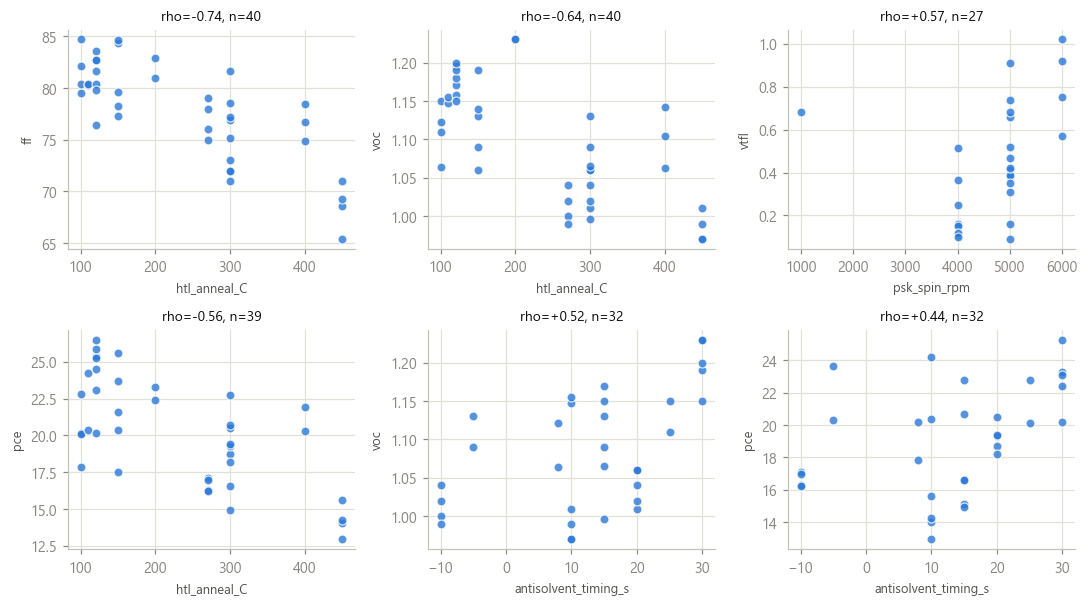

In [8]:
pairs = [(r.knob, r.y) for r in top.itertuples()][:6]
if pairs:
    fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
    for ax, (k, y) in zip(axes.ravel(), pairs + [(None, None)] * (6 - len(pairs))):
        if k is None:
            ax.axis("off"); continue
        s = tt[[k, y]].dropna()
        ax.scatter(s[k], s[y], color=C1, s=34, alpha=0.8, edgecolor="white", linewidth=0.8)
        rho, _ = ss.spearmanr(s[k], s[y])
        ax.set_xlabel(k, fontsize=8.5); ax.set_ylabel(y, fontsize=8.5)
        ax.set_title(f"rho={rho:+.2f}, n={len(s)}", fontsize=9)
    plt.tight_layout(); plt.show()

## 7. Composition (X ควบคุม) — a_Cs / a_FA / x_Br

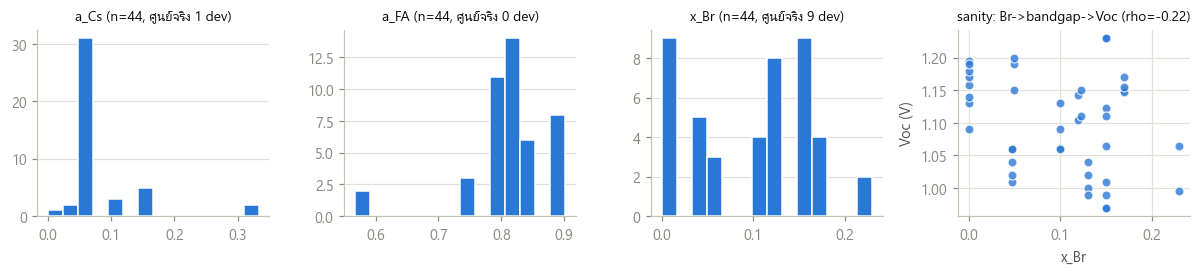

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6))
for ax, c in zip(axes[:3], ["a_Cs", "a_FA", "x_Br"]):
    ax.hist(tt[c].dropna(), bins=14, color=C1, edgecolor="white", linewidth=1)
    ax.set_title(f"{c} (n={int(tt[c].notna().sum())}, ศูนย์จริง {int((tt[c] == 0).sum())} dev)", fontsize=9)
    ax.grid(axis="x", visible=False)

s = tt.dropna(subset=["x_Br", "voc"])
axes[3].scatter(s.x_Br, s.voc, color=C1, s=34, alpha=0.8, edgecolor="white", linewidth=0.8)
rho, pv = ss.spearmanr(s.x_Br, s.voc)
axes[3].set_xlabel("x_Br"); axes[3].set_ylabel("Voc (V)")
axes[3].set_title(f"sanity: Br->bandgap->Voc (rho={rho:+.2f})", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Stability (exploratory, n=14)

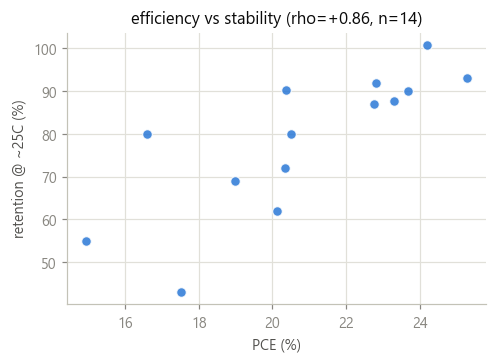

n=14 จาก paper ไม่กี่ฉบับ -- ใช้ตั้งสมมุติฐานเท่านั้น อย่าสรุป


In [10]:
s = tt.dropna(subset=["retention_25c", "pce"])
fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.scatter(s.pce, s.retention_25c, color=C1, s=40, alpha=0.85, edgecolor="white", linewidth=0.8)
rho, pv = ss.spearmanr(s.pce, s.retention_25c)
ax.set_xlabel("PCE (%)"); ax.set_ylabel("retention @ ~25C (%)")
ax.set_title(f"efficiency vs stability (rho={rho:+.2f}, n={len(s)})")
plt.tight_layout(); plt.show()
print("n=14 จาก paper ไม่กี่ฉบับ -- ใช้ตั้งสมมุติฐานเท่านั้น อย่าสรุป")

## 9. Missingness — แถว = device (เรียงตาม paper), คอลัมน์ = ตัวแปร

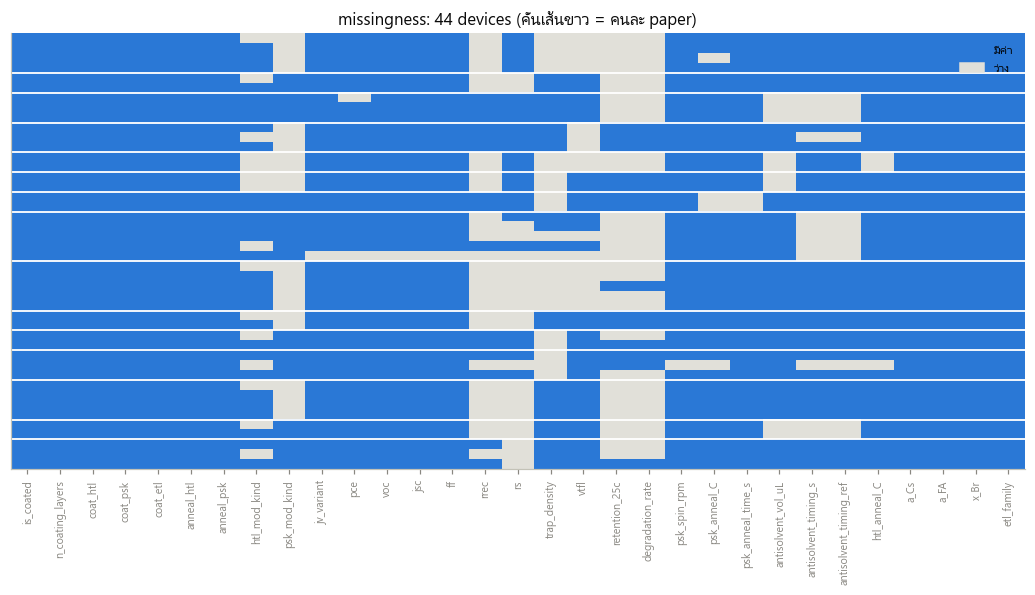

แถบว่างมักว่างทั้ง paper (ไม่รายงาน) ไม่ใช่กรอกตก -> missing = MNAR ระดับ paper, ห้าม impute ข้าม paper


In [11]:
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

cols = [c for c in tt.columns if c not in ("device_id", "paper")]
M = tt.sort_values("paper")[cols].notna().astype(int)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.imshow(M.values, aspect="auto", cmap=ListedColormap([GRID, C1]), interpolation="nearest")
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=7)
ax.set_yticks([]); ax.grid(visible=False)
# เส้นแบ่ง paper
b = tt.sort_values("paper")["paper"].values
for i in range(1, len(b)):
    if b[i] != b[i - 1]:
        ax.axhline(i - 0.5, color="white", lw=1.2)
ax.legend(handles=[mpatches.Patch(color=C1, label="มีค่า"), mpatches.Patch(color=GRID, label="ว่าง")],
          loc="upper right", fontsize=8, frameon=False)
ax.set_title("missingness: 44 devices (คั่นเส้นขาว = คนละ paper)")
plt.tight_layout(); plt.show()
print("แถบว่างมักว่างทั้ง paper (ไม่รายงาน) ไม่ใช่กรอกตก -> missing = MNAR ระดับ paper, ห้าม impute ข้าม paper")

## 10. Explore รายไฟล์ (ที่เหลือนอกจาก target_table)

`target_table` ครอบคลุมใน §1-8 แล้ว — ส่วนนี้ไล่ไฟล์ที่เหลือทีละไฟล์: โครง, การกระจาย, จุดระวังเฉพาะไฟล์

### 10.1 `devices` + `device_layer_flags` — ทะเบียน device + ธง layer

ธง (จำนวน device ที่ True): {'is_coated': 44, 'coat_htl': 26, 'coat_psk': 22, 'coat_etl': 44, 'anneal_htl': 44, 'anneal_psk': 42}
n_coating_layers: {1: 12, 2: 16, 3: 16}


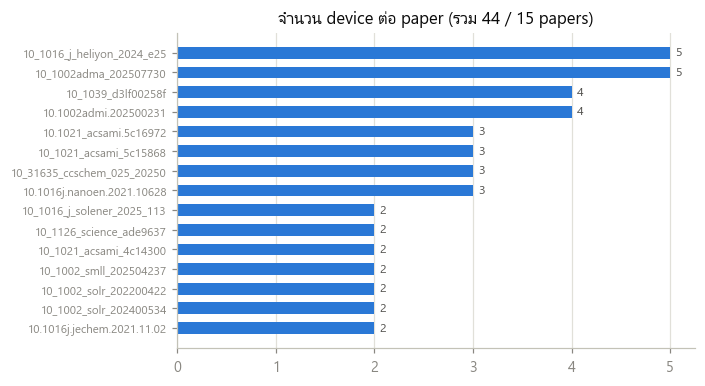

device_layer_flags.csv = ธงชุดเดียวกันแยกไฟล์ (ซ้ำกับใน devices/target_table)


In [12]:
dv = t["devices"]
fl = ["is_coated", "coat_htl", "coat_psk", "coat_etl", "anneal_htl", "anneal_psk"]
print("ธง (จำนวน device ที่ True):", dv[fl].sum().to_dict())
print("n_coating_layers:", dv["n_coating_layers"].value_counts().sort_index().to_dict())

per = tt.groupby("paper")["device_id"].count().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(per.index.str[:26], per.values, color=C1, height=0.6)
for i, v in enumerate(per.values):
    ax.text(v + 0.05, i, str(v), va="center", color=INK2, fontsize=8)
ax.grid(axis="y", visible=False); ax.set_title("จำนวน device ต่อ paper (รวม 44 / 15 papers)")
ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); plt.show()
print("device_layer_flags.csv = ธงชุดเดียวกันแยกไฟล์ (ซ้ำกับใน devices/target_table)")

### 10.2 `layers` — โครงชั้น + ความหนา

key `(device_id, layer_id)` **ไม่ unique** — layer 7 มีได้ 2 วัสดุ (PCBM+BCP)

layer_kind: {'main': 218, 'coating': 94, nan: 37, 'additive': 3}
รายชั้น (n_rows > n_dev = ชั้นนั้นมีหลายวัสดุ):


,n_rows,n_dev,th_cov
layer_id,,,
1,44,44,0
2,44,44,14
3,44,44,0
4,44,44,11
5,44,44,0
6,44,44,15
7,46,44,23
8,42,42,42


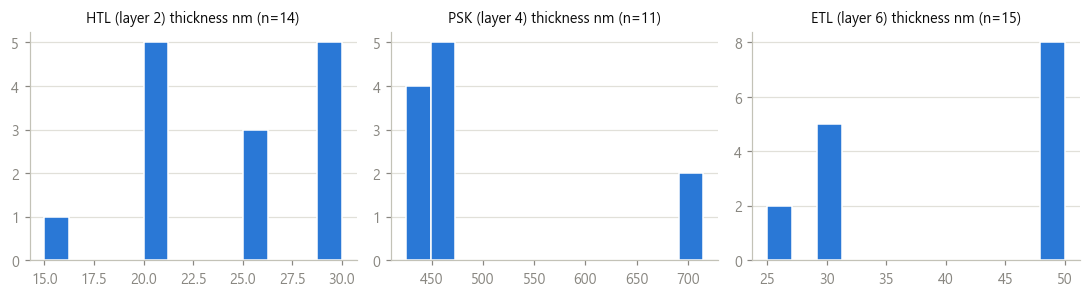

material_family top: {'TCO': 44, 'NiOx': 44, 'Metal electrode': 44, 'BCP': 40, 'PCBM': 28, 'Amine passivation': 24, 'C60': 18, 'SAM (xPACz)': 8}


In [13]:
la = t["layers"]
print("layer_kind:", la["layer_kind"].value_counts(dropna=False).to_dict())
chk = la.groupby(["layer_id"]).agg(n_rows=("device_id", "size"), n_dev=("device_id", "nunique"),
                                   th_cov=("thickness_nm_parsed", lambda s: s.notna().sum()))
print("รายชั้น (n_rows > n_dev = ชั้นนั้นมีหลายวัสดุ):"); display(chk)

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, lid, name in zip(axes, [2, 4, 6], ["HTL (layer 2)", "PSK (layer 4)", "ETL (layer 6)"]):
    v = la.loc[la.layer_id == lid, "thickness_nm_parsed"].dropna()
    ax.hist(v, bins=12, color=C1, edgecolor="white", linewidth=1)
    ax.set_title(f"{name} thickness nm (n={len(v)})", fontsize=9.5)
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("material_family top:", la["material_family"].value_counts().head(8).to_dict())

### 10.3 `materials` — สารตั้งต้น + solvent

type: {nan: 168, 'Precursor': 155, 'Solution': 126, 'Additive': 29, 'Substrate': 19, 'Nanoparticles': 9, 'Antisolvent': 6, 'SAM': 5, 'Surface modifier': 4, 'Interlayer': 4, 'PSK surface treatment': 3, 'Metal': 2, 'SAM solution': 2, 'ETL': 2, 'Nanoparticle ink': 2, 'Nanoparticle': 1, 'Nanoparticle dispersion': 1, 'SAM passivation layer': 1, 'Co-modifier/SAM filler': 1, 'ETL additive': 1, 'Cathode': 1, 'Precursor (10% excess)': 1}
unit ของ amount: {'mg': 97, 'mg mL-1': 88, 'M': 39, 'mg/mL': 22, 'mol%': 21, 'µL': 12, 'g / 2mL': 8, 'mmol': 6, 'g per 10 mL': 5, 'mL per 10 mL': 5}


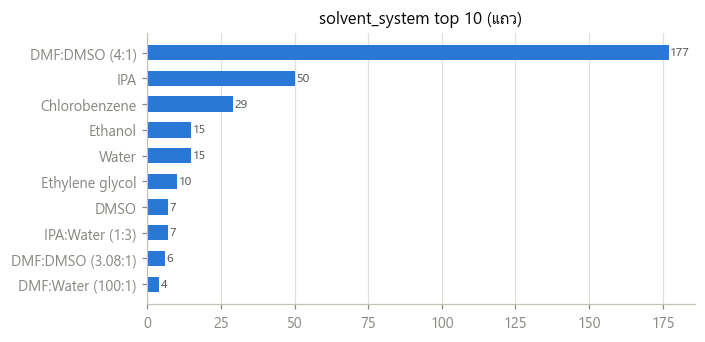

solvent_ratio ตัวอย่าง: [4.00e+00 3.33e-01 3.08e+00 1.00e+02 7.00e-03]


In [14]:
ma = t["materials"]
print("type:", ma["type"].value_counts(dropna=False).to_dict())
print("unit ของ amount:", ma["unit"].value_counts().head(10).to_dict())

ss_top = ma["solvent_system"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(ss_top.index, ss_top.values, color=C1, height=0.6)
for i, v in enumerate(ss_top.values):
    ax.text(v + 0.5, i, str(v), va="center", color=INK2, fontsize=8)
ax.grid(axis="y", visible=False); ax.set_title("solvent_system top 10 (แถว)")
plt.tight_layout(); plt.show()
print("solvent_ratio ตัวอย่าง:", ma["solvent_ratio"].dropna().unique()[:8])

### 10.4 `process` — ขั้นตอน + 53 knob columns

⚠️ `Annealing__C` ปนทุก layer — filter `layer_id` ก่อนใช้เสมอ (HTL 270-450°C vs PSK 100-150°C)

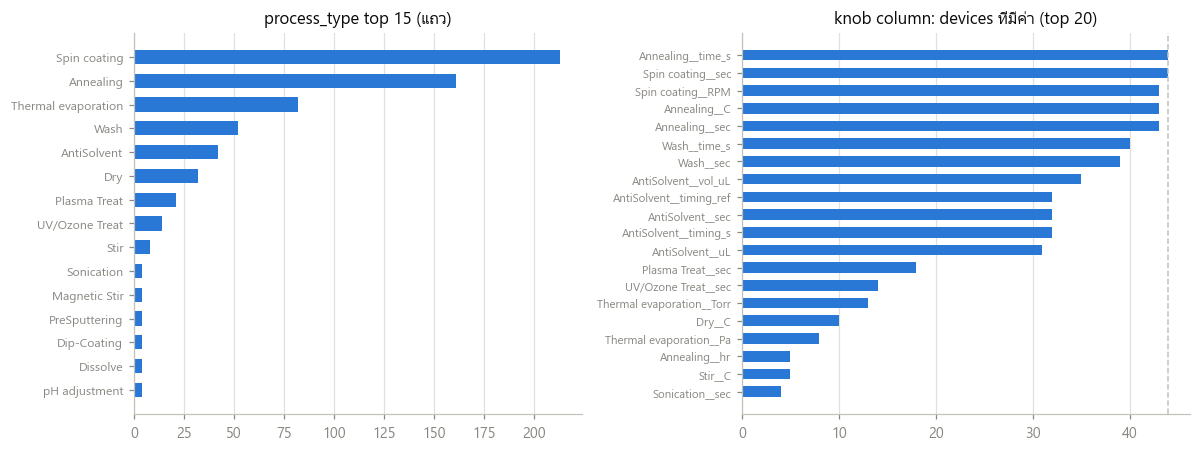

param_fixed: 8 แถว | ติดธง param_note: 1 แถว


,device_id,layer_id,process_type,parameter,unit,param_note
47,10.1002admi.202500231_Sample3,4,Annealing,100108000,"C, sec","param 1 ค่า != unit 2 ค่า: '100108000' | 'C, sec'"


anneal แยก layer (ยืนยันว่าคนละสเกล):


,count,min,median,max
layer_id,,,,
1,3,200.0,200.0,200.0
2,54,75.0,150.0,450.0
3,28,60.0,100.0,120.0
4,42,30.0,100.0,105.0
5,9,70.0,100.0,100.0
6,14,60.0,85.0,100.0
7,5,60.0,70.0,70.0


In [15]:
prc = t["process"]
top_pt = prc["process_type"].value_counts().head(15).sort_values()
kn = [c for c in prc.columns if "__" in c]
cov_k = pd.Series({c: prc.loc[prc[c].notna(), "device_id"].nunique() for c in kn})
cov_k = cov_k[cov_k > 0].sort_values().tail(20)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(top_pt.index, top_pt.values, color=C1, height=0.6)
axes[0].set_title("process_type top 15 (แถว)"); axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(cov_k.index, cov_k.values, color=C1, height=0.6)
axes[1].axvline(44, color=BASE, lw=1, ls="--")
axes[1].set_title("knob column: devices ที่มีค่า (top 20)"); axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); plt.show()

print(f"param_fixed: {int(prc['param_fixed'].sum())} แถว | ติดธง param_note: {int(prc['param_note'].notna().sum())} แถว")
display(prc.loc[prc["param_note"].notna(), ["device_id", "layer_id", "process_type", "parameter", "unit", "param_note"]])
print("anneal แยก layer (ยืนยันว่าคนละสเกล):")
display(prc[prc.process_type == "Annealing"].dropna(subset=["Annealing__C"])
        .groupby("layer_id")["Annealing__C"].agg(["count", "min", "median", "max"]))

### 10.5 `properties` — ทุกค่าที่ paper รายงาน

device เดียวมีหลายแถวต่อ property (Champion/Average/scan) — pivot เองต้องเลือก variant ให้ตรงกัน

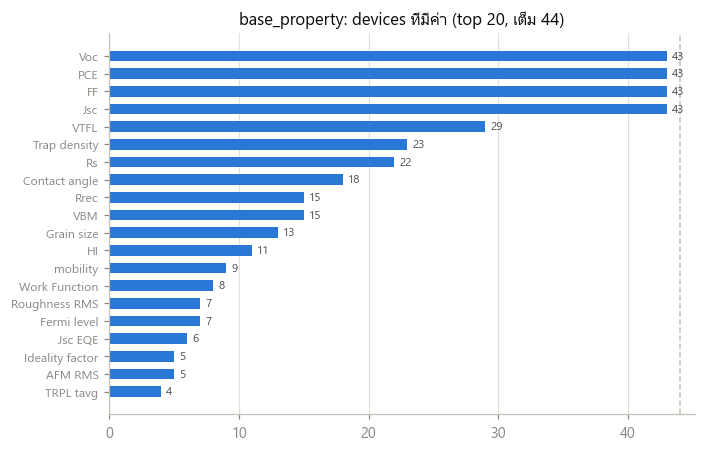

stat: {nan: 379, 'champion': 116, 'average': 61, 'avg': 4, 'certified': 2, 'verified': 1}
scan: {nan: 457, 'RS': 61, 'FS': 45}
value_parsed ว่าง: 19/563 แถว (ค่า text เช่น 'Yes'/สัญลักษณ์)


In [16]:
pp = t["properties"]
cov_p = (pp.dropna(subset=["value_parsed"]).groupby("base_property")["device_id"]
         .nunique().sort_values().tail(20))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(cov_p.index, cov_p.values, color=C1, height=0.6)
ax.axvline(44, color=BASE, lw=1, ls="--")
for i, v in enumerate(cov_p.values):
    ax.text(v + 0.4, i, str(v), va="center", color=INK2, fontsize=7.5)
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
ax.set_title("base_property: devices ที่มีค่า (top 20, เต็ม 44)")
plt.tight_layout(); plt.show()
print("stat:", pp["stat"].value_counts(dropna=False).head(6).to_dict())
print("scan:", pp["scan"].value_counts(dropna=False).head(6).to_dict())
print(f"value_parsed ว่าง: {int(pp['value_parsed'].isna().sum())}/{len(pp)} แถว (ค่า text เช่น 'Yes'/สัญลักษณ์)")

### 10.6 `psk_composition` — องค์ประกอบ PSK ต่อ device

NaN ใน `a_*`/`x_*` = ไอออนไม่อยู่ในสูตร (=0 จริง) — ไฟล์นี้เก็บค่าดิบ target_table fill 0 แล้ว

comp_source: {'formula': 42, 'precursor': 2}
cross_check: {'(ไม่มี precursor เทียบ)': 27, 'ตรง': 13, '-- (สูตรแตกไม่ได้)': 2, 'ต่าง': 2}


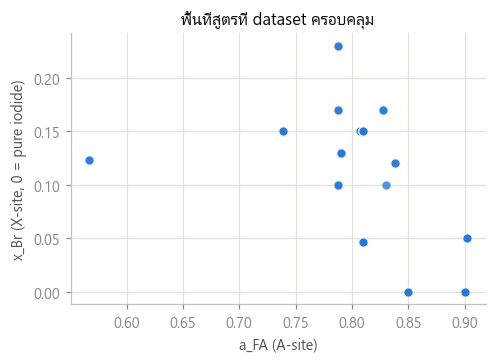

เคส cross_check ต่าง:


,device_id,layer_material,cross_check
16,10_1002_solr_202400534_Sample1,Cs0.05(FA0.83MA0.12)0.95Pb(I0.83Br0.17)3,"ต่าง: Br, I"
17,10_1002_solr_202400534_Sample2,Cs0.05(FA0.83MA0.12)0.95Pb(I0.83Br0.17)3 + TFM...,"ต่าง: Br, I"


In [17]:
pc = t["psk_composition"]
print("comp_source:", pc["comp_source"].value_counts().to_dict())
print("cross_check:", pc["cross_check"].fillna("(ไม่มี precursor เทียบ)").str.split(":").str[0].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(4.6, 3.4))
s = pc.dropna(subset=["a_FA"]).copy()
s["x_Br0"] = s["x_Br"].fillna(0)
ax.scatter(s["a_FA"], s["x_Br0"], color=C1, s=38, alpha=0.8, edgecolor="white", linewidth=0.8)
ax.set_xlabel("a_FA (A-site)"); ax.set_ylabel("x_Br (X-site, 0 = pure iodide)")
ax.set_title("พื้นที่สูตรที่ dataset ครอบคลุม")
plt.tight_layout(); plt.show()
print("เคส cross_check ต่าง:")
display(pc[pc["cross_check"].fillna("").str.startswith("ต่าง")][["device_id", "layer_material", "cross_check"]])

### 10.7 `stability` — การทดสอบรายเงื่อนไข (62 แถว / 35 dev)

เทียบข้ามเงื่อนไขตรง ๆ ไม่ได้ — อุณหภูมิ 25-85°C เวลา 1-5000 ชม.

stress_group: {'light/operational': 20, 'inert (N2)': 16, 'ambient air': 13, 'thermal': 5, 'dark storage': 5, 'other': 3}
censored (<55): 1 แถว


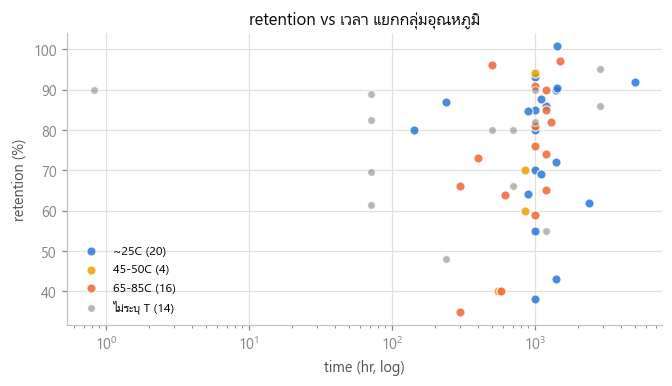

In [18]:
st = t["stability"]
print("stress_group:", st["stress_group"].value_counts(dropna=False).to_dict())
print("censored (<55):", int(st["retention_pct_censor"].notna().sum()), "แถว")

s = st.dropna(subset=["retention_pct_parsed", "time_hr"]).copy()
Tp = pd.to_numeric(s["temperature_c_parsed"], errors="coerce")
grp = pd.cut(Tp, [0, 30, 60, 100], labels=["~25C", "45-50C", "65-85C"])
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for g, c in [("~25C", C1), ("45-50C", C4), ("65-85C", C2)]:
    m = grp == g
    ax.scatter(s.loc[m, "time_hr"], s.loc[m, "retention_pct_parsed"],
               color=c, s=36, alpha=0.85, edgecolor="white", linewidth=0.8, label=f"{g} ({int(m.sum())})")
m = grp.isna()
ax.scatter(s.loc[m, "time_hr"], s.loc[m, "retention_pct_parsed"],
           color=MUTED, s=26, alpha=0.6, edgecolor="white", linewidth=0.8, label=f"ไม่ระบุ T ({int(m.sum())})")
ax.set_xscale("log"); ax.set_xlabel("time (hr, log)"); ax.set_ylabel("retention (%)")
ax.legend(fontsize=8, frameon=False); ax.set_title("retention vs เวลา แยกกลุ่มอุณหภูมิ")
plt.tight_layout(); plt.show()

### 10.8 `vendors` — provenance (ไม่ใช่ feature)

In [19]:
vd = t["vendors"]
print("purity_kind:", vd["purity_kind"].value_counts(dropna=False).to_dict())
print("purity_pct: n=", int(vd["purity_pct"].notna().sum()),
      "median=", vd["purity_pct"].median())
print("vendor top:", vd["vendor"].value_counts().head(8).to_dict())
print("ใช้เป็นข้อมูลอ้างอิงตอนเขียน methods/จัดซื้อสารทำแล็บ ไม่เข้าโมเดล")

purity_kind: {'missing': 315, 'percent': 298, 'percent_lower_bound': 18, 'grade_descriptor': 6, 'sheet_resistance_misfiled': 4, 'concentration_wt_pct': 3}
purity_pct: n= 316 median= 99.8
vendor top: {'Sigma-Aldrich': 100, 'Alfa Aesar': 56, 'Advanced Election Technology Co., Ltd.': 37, 'Xian Yuri Solar Co., Ltd.': 28, 'TCI': 25, 'Xi-an Polymer Light Technology Corp.': 25, 'Aladdin': 24, 'Lumtec': 21}
ใช้เป็นข้อมูลอ้างอิงตอนเขียน methods/จัดซื้อสารทำแล็บ ไม่เข้าโมเดล


## 11. ข้อสังเกต (จากรอบนี้)

1. **confound ระหว่าง paper ใหญ่มาก** — variance ระหว่าง paper >> ใน paper ยืนยันว่า LOPO จำเป็น ไม่ใช่แค่ formality
2. **coverage 3 ชั้นชัดเจน**: JV+knob+composition (~40-44) / mediator+antisolvent (~20-35) / stability (~14) — โมเดลหลักควรอยู่ชั้นแรก ชั้นหลังเป็น exploratory
3. **คู่ knob-Y ที่ |rho|≥0.3** เป็น candidate เข้า LOPO — ห้ามตีความเป็น causal ตอนนี้
4. **missing เป็นระดับ paper (MNAR)** — ห้าม impute ข้าม paper ใช้ model ที่ทน missing (RF) หรือ subset ตาม coverage
5. antisolvent timing มี 2 จุดอ้างอิง — ใช้ per-group หรือทำ feature `dripped_late` แบบ binary แทนค่าต่อเนื่อง

**ต่อไป**: RandomForest + SHAP บนชั้น coverage แรก, LeaveOneGroupOut(paper), รายงาน mean±SD + bootstrap